1. Load and combine fold-level result files

In [1]:
# --------------------------------------------------
# 0. Import
# --------------------------------------------------

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# --------------------------------------------------
# 1. Load fold-level result files
# --------------------------------------------------

file_paths = [
    "ml_fold_level_results_match_nonmatch.csv",
    "cnn_fold_level_results_match_nonmatch.csv",
    "bert_scibert_fold_level_results_match_nonmatch.csv",
    "chatgpt_zero_shot_fold_level_results_match_nonmatch.csv",
    "chatgpt_few_shot_fold_level_results_match_nonmatch.csv"
]

dfs = []

for path in file_paths:
    temp_df = pd.read_csv(path, encoding="utf-8-sig")
    dfs.append(temp_df)

results_df = pd.concat(dfs, ignore_index=True)

In [3]:
# --------------------------------------------------
# 2. User-adjustable model order and display names
# --------------------------------------------------

# Check actual model names if needed
print(results_df["Model"].unique())

# Define the desired model order based on the actual names in your CSV files
MODEL_ORDER = [
    "LogisticRegression",
    "RandomForest",
    "CNN",
    "BERT",
    "SciBERT",
    "ChatGPT_zero_shot",
    "ChatGPT_few_shot"
]

# Define display names for figures
# You can modify these names later, e.g., "LogisticRegression": "LR"
MODEL_NAME_MAP = {
    "LogisticRegression": "LR",
    "RandomForest": "RF",
    "CNN": "CNN",
    "BERT": "BERT",
    "SciBERT": "SciBERT",
#     "ChatGPT_zero_shot": "ChatGPT\nZero-shot",
#     "ChatGPT_few_shot": "ChatGPT\nFew-shot",
    "ChatGPT_zero_shot": "GPT_ZS",
    "ChatGPT_few_shot": "GPT_FS"
}

# Apply display names
results_df["Model_Display"] = results_df["Model"].map(MODEL_NAME_MAP)

# Keep only models in the desired order
results_df = results_df[results_df["Model"].isin(MODEL_ORDER)].copy()

# Create ordered display names
DISPLAY_ORDER = [MODEL_NAME_MAP[m] for m in MODEL_ORDER]

results_df["Model_Display"] = pd.Categorical(
    results_df["Model_Display"],
    categories=DISPLAY_ORDER,
    ordered=True
)

['LogisticRegression' 'RandomForest' 'CNN' 'BERT' 'SciBERT'
 'ChatGPT_zero_shot' 'ChatGPT_few_shot']


Positive pairs (Match): Precision, Recall, F1 boxplots in one figure

In [4]:
# --------------------------------------------------
# 3. Reshape Match metrics into long format
# --------------------------------------------------

match_metrics = [
    "Match_Precision",
    "Match_Recall",
    "Match_F1"
]

match_long = results_df.melt(
    id_vars=["Fold", "Model_Display"],
    value_vars=match_metrics,
    var_name="Metric",
    value_name="Score"
)

# Clean metric names
match_long["Metric"] = match_long["Metric"].str.replace("Match_", "", regex=False)

In [5]:
# --------------------------------------------------
# 4. User-adjustable figure settings
# --------------------------------------------------

FIG_WIDTH = 24
FIG_HEIGHT = 6

TITLE_SIZE = 18
LABEL_SIZE = 16
TICK_SIZE = 14
SUPTITLE_SIZE = 20

BOX_WIDTH = 0.7

Y_MIN = 0.0
Y_MAX = 1.05
Y_TICK_STEP = 0.1
Y_TICKS = np.arange(Y_MIN, Y_MAX + 0.001, Y_TICK_STEP)

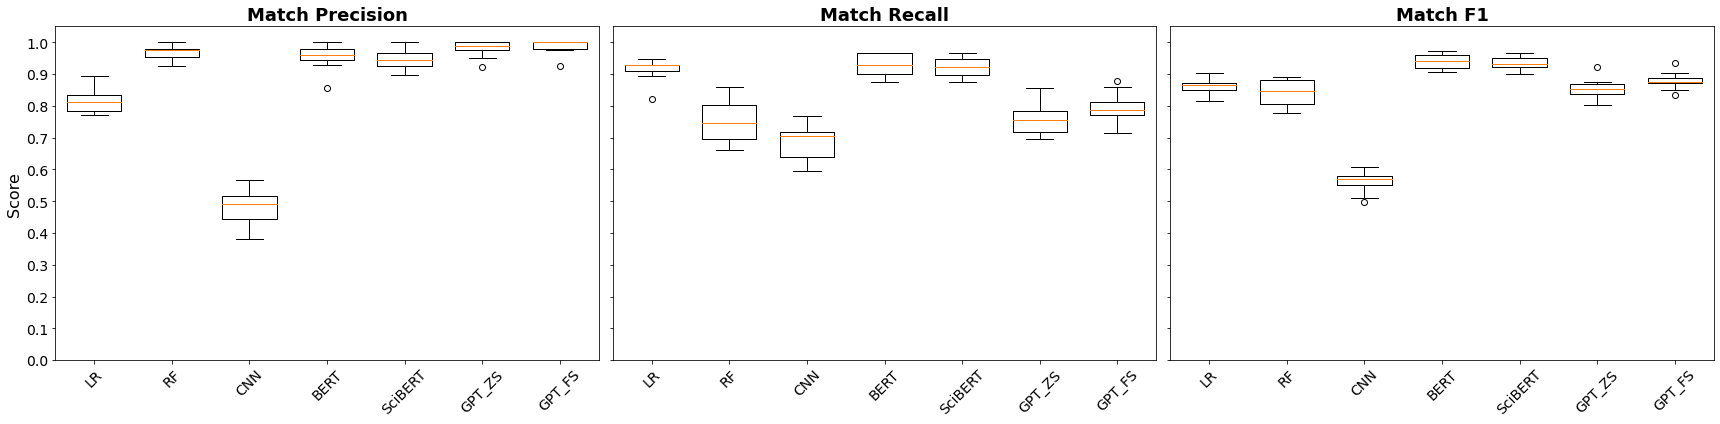

In [6]:
# --------------------------------------------------
# 5. Plot Match Precision, Recall, and F1 side by side
# --------------------------------------------------


fig, axes = plt.subplots(
    1, 3,
    figsize=(FIG_WIDTH, FIG_HEIGHT),
    sharey=True
)

for ax, metric in zip(axes, ["Precision", "Recall", "F1"]):
    temp = match_long[match_long["Metric"] == metric].copy()
    
    data_to_plot = [
        temp[temp["Model_Display"] == model]["Score"].dropna().values
        for model in DISPLAY_ORDER
    ]
    
    ax.boxplot(
        data_to_plot,
        labels=DISPLAY_ORDER,
        showmeans=False,
        widths=BOX_WIDTH
    )
    
    ax.set_title(
        f"Match {metric}",
        fontsize=TITLE_SIZE,
        fontweight="bold"
    )
    
#     ax.set_xlabel(
#         "Model",
#         fontsize=LABEL_SIZE
#     )
    
    ax.set_ylim(Y_MIN, Y_MAX)
    ax.set_yticks(Y_TICKS)
    
    ax.tick_params(
        axis="x",
        rotation=45,
        labelsize=TICK_SIZE
    )
    
    ax.tick_params(
        axis="y",
        labelsize=TICK_SIZE
    )

axes[0].set_ylabel(
    "Score",
    fontsize=LABEL_SIZE
)

# fig.suptitle(
#     "Fold-level Variability for Positive Pairs (Match)",
#     fontsize=SUPTITLE_SIZE,
#     fontweight="bold"
# )

plt.tight_layout()

plt.savefig(
    "match_boxplot_precision_recall_f1_custom_largefont.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Negative pairs (NonMatch): Precision, Recall, F1 boxplots in one figure

In [7]:
# --------------------------------------------------
# 6. Reshape NonMatch metrics into long format
# --------------------------------------------------

nonmatch_metrics = [
    "NonMatch_Precision",
    "NonMatch_Recall",
    "NonMatch_F1"
]

nonmatch_long = results_df.melt(
    id_vars=["Fold", "Model_Display"],
    value_vars=nonmatch_metrics,
    var_name="Metric",
    value_name="Score"
)

# Clean metric names
nonmatch_long["Metric"] = nonmatch_long["Metric"].str.replace("NonMatch_", "", regex=False)

In [8]:
# --------------------------------------------------
# 7. User-adjustable figure settings
# --------------------------------------------------

FIG_WIDTH = 24
FIG_HEIGHT = 6

TITLE_SIZE = 18
LABEL_SIZE = 16
TICK_SIZE = 14
SUPTITLE_SIZE = 20

BOX_WIDTH = 0.7

Y_MIN = 0.7
Y_MAX = 1.02
Y_TICK_STEP = 0.05
Y_TICKS = np.arange(Y_MIN, Y_MAX + 0.001, Y_TICK_STEP)

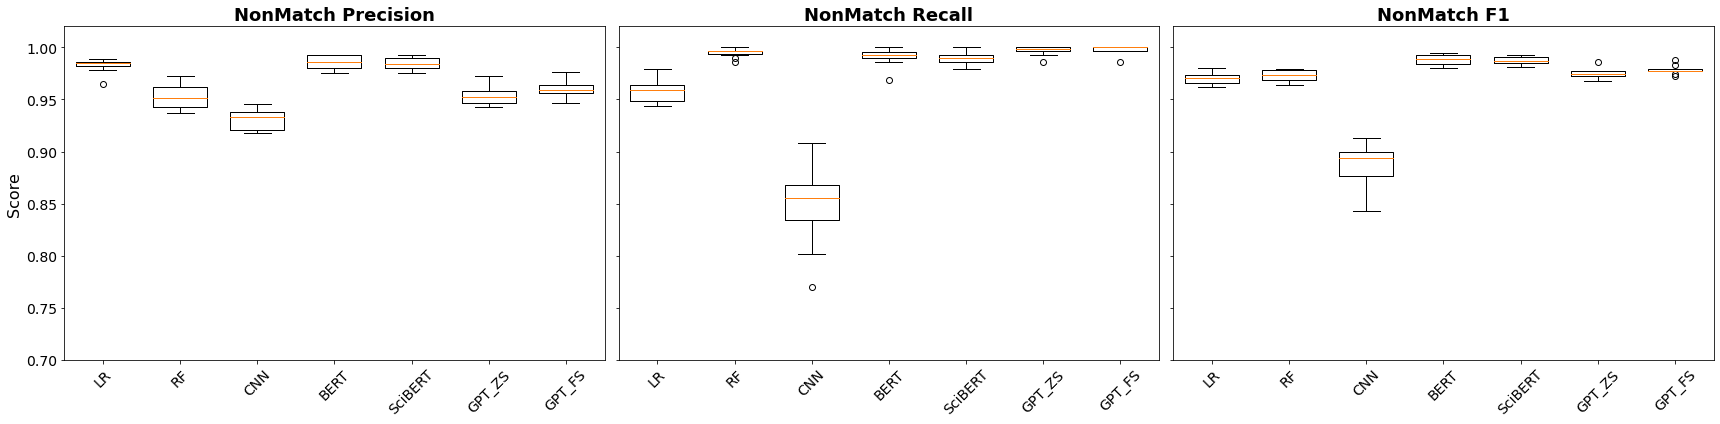

In [9]:
# --------------------------------------------------
# 8. Plot NonMatch Precision, Recall, and F1 side by side
# --------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(FIG_WIDTH, FIG_HEIGHT),
    sharey=True
)

for ax, metric in zip(axes, ["Precision", "Recall", "F1"]):
    temp = nonmatch_long[nonmatch_long["Metric"] == metric].copy()
    
    data_to_plot = [
        temp[temp["Model_Display"] == model]["Score"].dropna().values
        for model in DISPLAY_ORDER
    ]
    
    ax.boxplot(
        data_to_plot,
        labels=DISPLAY_ORDER,
        showmeans=False,
        widths=BOX_WIDTH
    )
    
    ax.set_title(
        f"NonMatch {metric}",
        fontsize=TITLE_SIZE,
        fontweight="bold"
    )
    
#     ax.set_xlabel(
#         "Model",
#         fontsize=LABEL_SIZE
#     )
    
    ax.set_ylim(Y_MIN, Y_MAX)
    ax.set_yticks(Y_TICKS)
    
    ax.tick_params(
        axis="x",
        rotation=45,
        labelsize=TICK_SIZE
    )
    
    ax.tick_params(
        axis="y",
        labelsize=TICK_SIZE
    )

axes[0].set_ylabel(
    "Score",
    fontsize=LABEL_SIZE
)

# fig.suptitle(
#     "Fold-level Variability for Negative Pairs (NonMatch)",
#     fontsize=SUPTITLE_SIZE,
#     fontweight="bold"
# )

plt.tight_layout()

plt.savefig(
    "nonmatch_boxplot_precision_recall_f1_custom_largefont.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()